PROYECTO FÍSICA COMPUTACIONAL 2026-II
SANTIAGO RIVERA HERNÁNDEZ

CONTEXTO EXPERIMENTAL

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

datos = {
    "Exoplaneta": [
        "TRAPPIST-1b",
        "TRAPPIST-1c",
        "TRAPPIST-1d",
        "TRAPPIST-1e",
        "TRAPPIST-1f",
        "TRAPPIST-1g",
        "TRAPPIST-1h",
    ],
    "aUA": [
        0.01154,
        0.01580,
        0.02227,
        0.02925,
        0.03849,
        0.04683,
        0.06189,
    ],
    "Tdias": [
        1.51087,
        2.42182,
        4.04961,
        6.09961,
        9.20669,
        12.3529,
        18.7679,
    ],
}

tabla = pd.DataFrame(datos)
print(tabla)

    Exoplaneta      aUA     Tdias
0  TRAPPIST-1b  0.01154   1.51087
1  TRAPPIST-1c  0.01580   2.42182
2  TRAPPIST-1d  0.02227   4.04961
3  TRAPPIST-1e  0.02925   6.09961
4  TRAPPIST-1f  0.03849   9.20669
5  TRAPPIST-1g  0.04683  12.35290
6  TRAPPIST-1h  0.06189  18.76790


CONVERSIÓN DE UNIDADES

In [10]:
tabla["aSI"] = tabla["aUA"] * 1.495978707e11
tabla["TSI"] = tabla["Tdias"] * 86400
print(tabla)

    Exoplaneta      aUA     Tdias           aSI          TSI
0  TRAPPIST-1b  0.01154   1.51087  1.726359e+09   130539.168
1  TRAPPIST-1c  0.01580   2.42182  2.363646e+09   209245.248
2  TRAPPIST-1d  0.02227   4.04961  3.331545e+09   349886.304
3  TRAPPIST-1e  0.02925   6.09961  4.375738e+09   527006.304
4  TRAPPIST-1f  0.03849   9.20669  5.758022e+09   795458.016
5  TRAPPIST-1g  0.04683  12.35290  7.005668e+09  1067290.560
6  TRAPPIST-1h  0.06189  18.76790  9.258612e+09  1621546.560


In [11]:
def kEnFuncionT(a, k):
    return k * a**(3/2)

valores, covarianza = sp.optimize.curve_fit(kEnFuncionT, tabla["aSI"], tabla["TSI"])

k = valores [0]

"""Para la incertidumbre de la masa, necesitaremos la incertidumbre de k"""
incertidumbre_k = np.sqrt(covarianza[0, 0])

G = 6.6743e-11
M = 4 * np.pi**2 / (k**2 * G)

incertidumbre_M = 2 * M * (incertidumbre_k / k)

In [12]:
print(k)
print(incertidumbre_M)
print(M)

1.820234882973619e-09
1.755590455818721e+25
1.7852504334894925e+29


In [13]:
MSol = 1.98847e30
MTS = M / MSol
pMTS = MTS * 100
"""El periodo depende de la constante k, que incluye la masa de la estrella, y la distancia de los planetas a dicha estrella
en el semieje mayor, la conclusión lógica, es que los planetas de TRAPPIST están mucho más cerca a ella que los planetas
que orbitamos el sol"""

'El periodo depende de la constante k, que incluye la masa de la estrella, y la distancia de los planetas a dicha estrella\nen el semieje mayor, la conclusión lógica, es que los planetas de TRAPPIST están mucho más cerca a ella que los planetas\nque orbitamos el sol'

In [14]:
print(MTS)
print(pMTS)

0.08978010397388407
8.978010397388408


CURVA PARA EL SISTEMA SOLAR

In [15]:
"""Ya tenemos la masa del sol, entonces"""
kSol = 2 * np.pi / (np.sqrt(G * MSol))
aUA = np.linspace(0.01, 0.07, 100)
aM = aUA * 1.495978707e11
"""Como nos piden hacerlo en base a rangos de distancias de unidades astronómicas,
tiene sentido que el periodo lo calculemos en base a días terrestres, no en segundos"""

TSol = kSol * aM**(3/2) / 86400
TTRAPPIST = k * aM**(3/2) / 86400

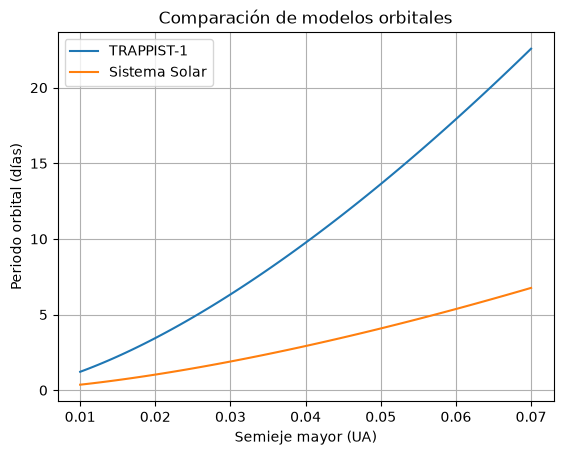

In [16]:
plt.plot(aUA, TTRAPPIST, label="TRAPPIST-1")
plt.plot(aUA, TSol, label="Sistema Solar")

plt.xlabel("Semieje mayor (UA)")
plt.ylabel("Periodo orbital (días)")
plt.title("Comparación de modelos orbitales")
plt.legend()
plt.grid()

plt.show()